# First look at real TESS data: Pi Mensae

This is an **EDA starting point**, using public observations of TIC 261136679 in sectors 1, 4, and 8. Pi Mensae is a known planet host used in [NASA's tutorial](https://heasarc.gsfc.nasa.gov/docs/tess/HowToFindAnExoplanet-UserVersion.html). We are inspecting the observations, not claiming a new discovery.

The notebook reads downloaded files locally and needs no network connection. Run all cells in order. Start with sector 1; the other sectors let you compare observing conditions and gaps.

Questions: What does brightness look like? How much is missing? What changes between sectors? How do SAP and PDCSAP differ? How much scatter remains after quality filtering?

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from lightkurve.utils import TessQualityFlags
from IPython.display import display

%matplotlib inline
ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data').exists(), 'Open this notebook from the project or notebooks folder.'
REPORTS = ROOT / 'reports'
PROCESSED = ROOT / 'data' / 'processed'
REPORTS.mkdir(exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})
manifest = json.loads((ROOT / 'data' / 'manifest_tic261136679.json').read_text())
display(pd.DataFrame(manifest['files'])[['sector', 'rows', 'cadence_seconds', 'date_obs', 'date_end', 'bytes']])

/Users/mikavohl/Projects/exoplanet/.venv/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


,sector,rows,cadence_seconds,date_obs,date_end,bytes
0,1,20076,120,2018-07-25T19:03:28.215,2018-08-22T16:14:49.298,2039040
1,4,18684,120,2018-10-19T09:34:53.187,2018-11-14T08:00:08.976,1897920
2,8,17755,120,2019-02-02T20:40:02.451,2019-02-27T11:58:41.948,1805760


## 1. Preserve the observations and inspect the schema

FITS is an astronomy file format containing arrays and descriptive headers. We keep the original files unchanged and verify their SHA-256 hashes against the download manifest.

- `TIME`: BTJD, or barycentric Julian date minus 2,457,000, in the TDB time scale; days, **not Unix timestamps**. The FITS headers specify the reference and time scale.
- `SAP_FLUX`: simple aperture photometry, in electrons per second. This is an extracted brightness measurement, not raw detector imagery.
- `PDCSAP_FLUX`: flux corrected by the SPOC pipeline for instrumental trends, with crowding/aperture corrections.
- `*_FLUX_ERR`: estimated uncertainty on the corresponding flux.
- `QUALITY`: a **bitmask** of observing/processing warnings, not a numeric score.

Missing data are real features of the observing process. Do not replace NaNs with zeros or interpolate gaps before a transit search.

In [2]:
columns = ['TIME', 'SAP_FLUX', 'SAP_FLUX_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR',
           'SAP_BKG', 'QUALITY', 'CADENCENO', 'MOM_CENTR1', 'MOM_CENTR2']
frames = []
for entry in manifest['files']:
    path = ROOT / entry['path']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == entry['sha256'], f'Changed file: {path}'
    with fits.open(path) as hdus:
        table = hdus[1].data
        # Convert FITS big-endian arrays to native byte order for pandas.
        frame = pd.DataFrame({name.lower(): np.array(table[name], dtype=table[name].dtype.newbyteorder('='))
                              for name in columns})
        frame['sector'] = entry['sector']
        frames.append(frame)
        print(f"Sector {entry['sector']}: {len(frame):,} rows; "
              f"time reference = {hdus[1].header.get('BJDREFI')} + {hdus[1].header.get('BJDREFF')}; "
              f"scale = {hdus[1].header.get('TIMESYS')}")
raw = pd.concat(frames, ignore_index=True)
display(raw.head())
display(raw.dtypes.to_frame('dtype'))

Sector 1: 20,076 rows; time reference = 2457000 + 0.0; scale = TDB
Sector 4: 18,684 rows; time reference = 2457000 + 0.0; scale = TDB
Sector 8: 17,755 rows; time reference = 2457000 + 0.0; scale = TDB


,time,sap_flux,sap_flux_err,pdcsap_flux,pdcsap_flux_err,sap_bkg,quality,cadenceno,mom_centr1,mom_centr2,sector
0,1325.295572,1435280.750,127.768387,NaN,NaN,4025.258789,8,70444,1630.736176,260.743145,1
1,1325.296960,1435492.625,127.761452,1464195.625,130.367188,3911.468750,0,70445,1630.676238,260.675401,1
2,1325.298349,1435719.875,127.752541,1464336.500,130.358093,3859.691895,0,70446,1630.648802,260.633919,1
3,1325.299738,1435658.750,127.753731,1464348.500,130.359314,3869.291992,0,70447,1630.648061,260.628400,1
4,1325.301127,1435619.000,127.744682,1464367.375,130.350082,3839.813232,0,70448,1630.647518,260.614342,1


,dtype
time,float64
sap_flux,float32
sap_flux_err,float32
pdcsap_flux,float32
pdcsap_flux_err,float32
sap_bkg,float32
quality,int32
cadenceno,int32
mom_centr1,float64
mom_centr2,float64


In [3]:
missing = raw.groupby('sector')[['time', 'sap_flux', 'pdcsap_flux', 'pdcsap_flux_err']].agg(lambda x: x.isna().sum())
display(missing.rename_axis(columns='missing values'))
print(f'Total original rows: {len(raw):,}')

missing values,time,sap_flux,pdcsap_flux,pdcsap_flux_err
sector,,,,
1,815,886,1797,1797
4,2711,2783,4012,4012
8,3200,3287,4819,4819


Total original rows: 56,515


## 2. Compare aperture and pipeline-corrected flux

Normalize each flux column by its own median **within each sector**. The sectors have different baselines, so raw flux levels should not be concatenated without normalization. These plots use all finite values, before quality filtering. Gray points indicate cadences flagged by Lightkurve's default policy.

A visible dip alone is insufficient evidence of a transit: spacecraft events, stellar variability, and contaminants can also change brightness.

Lightkurve default TESS quality bitmask: 17087


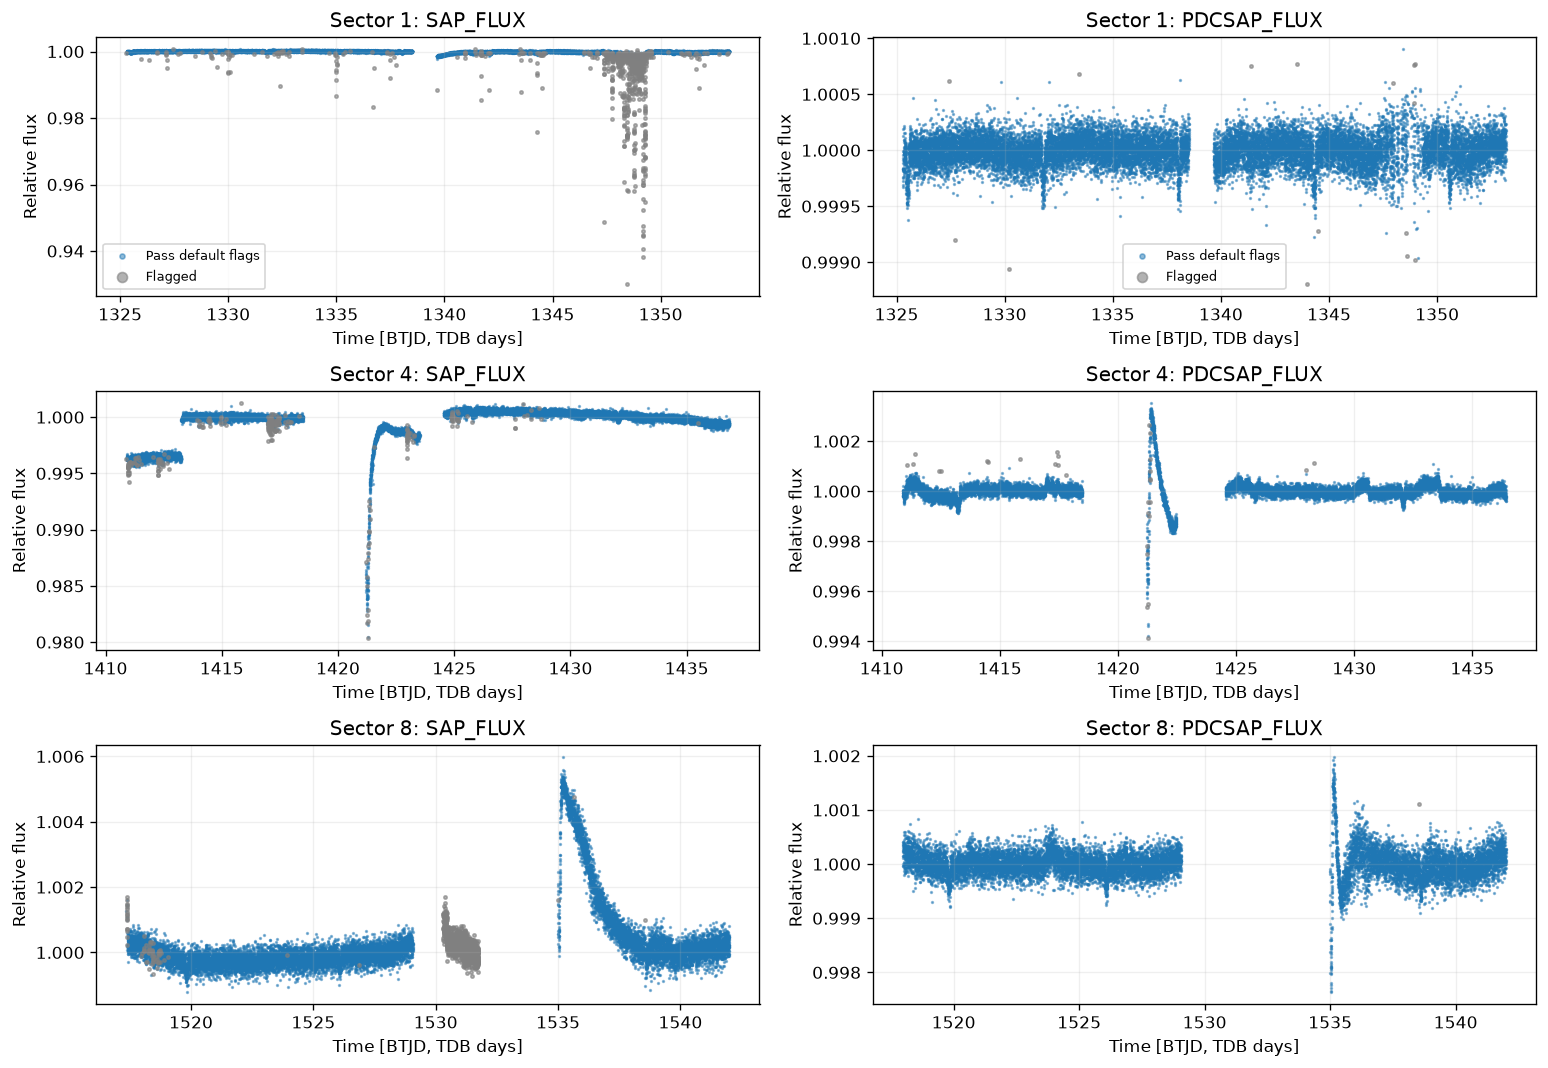

In [4]:
QUALITY_BITMASK = TessQualityFlags.DEFAULT_BITMASK
print(f"Lightkurve default TESS quality bitmask: {QUALITY_BITMASK}")
raw['quality_ok'] = (raw.quality.astype('int64') & QUALITY_BITMASK) == 0
for flux in ['sap_flux', 'pdcsap_flux']:
    medians = raw.groupby('sector')[flux].transform('median')
    raw[flux + '_norm'] = raw[flux] / medians
    raw[flux + '_err_norm'] = raw[flux + '_err'] / medians

sectors = sorted(raw.sector.unique())
fig, axes = plt.subplots(len(sectors), 2, figsize=(13, 3 * len(sectors)), squeeze=False)
for row, sector in enumerate(sectors):
    part = raw[raw.sector == sector]
    for col, flux in enumerate(['sap_flux', 'pdcsap_flux']):
        ax = axes[row, col]
        good = part[part.quality_ok]
        bad = part[~part.quality_ok]
        ax.scatter(good.time, good[flux + '_norm'], s=1, alpha=0.5, label='Pass default flags')
        ax.scatter(bad.time, bad[flux + '_norm'], s=4, color='gray', alpha=0.6, label='Flagged')
        ax.set(title=f'Sector {sector}: {flux.upper()}', xlabel='Time [BTJD, TDB days]', ylabel='Relative flux')
        if row == 0: ax.legend(markerscale=3, fontsize=8)
fig.tight_layout()
fig.savefig(REPORTS / '01_sap_vs_pdcsap.png', dpi=150)
plt.show()

## 3. Apply a transparent initial quality filter

Use Lightkurve's default TESS bitmask, finite time/PDCSAP flux/error, positive flux, and positive uncertainty. A nonzero quality value is not automatically rejected: the default mask selects specific bits.

We do **not** sigma-clip, flatten, or fill gaps here. Aggressive clipping could remove transits; detrending requires its own checks. Both the full table and this minimally filtered table are exported.

The rejection counts below can overlap: a row can be both flagged and missing.

In [5]:
finite = np.isfinite(raw[['time', 'pdcsap_flux', 'pdcsap_flux_err']]).all(axis=1)
positive = (raw.pdcsap_flux > 0) & (raw.pdcsap_flux_err > 0)
raw['valid_pdcsap'] = finite & positive
raw['keep'] = raw.quality_ok & raw.valid_pdcsap
clean = raw.loc[raw.keep].sort_values(['sector', 'time']).copy()
assert len(clean) > 0
assert not clean.duplicated(['sector', 'time']).any(), 'Duplicate retained times need investigation.'
for sector in sectors:
    assert (np.diff(clean.loc[clean.sector == sector, 'time']) > 0).all()

raw.to_csv(PROCESSED / 'pi_mensae_all_cadences.csv', index=False)
clean.to_csv(PROCESSED / 'pi_mensae_clean.csv', index=False)
display(raw.groupby('sector').agg(
    original_rows=('keep', 'size'), retained_rows=('keep', 'sum'),
    rejected_by_quality=('quality_ok', lambda x: (~x).sum()),
    invalid_pdcsap=('valid_pdcsap', lambda x: (~x).sum()),
))

,original_rows,retained_rows,rejected_by_quality,invalid_pdcsap
sector,,,,
1,20076,18264,1812,1797
4,18684,14642,1069,4012
8,17755,12935,2052,4819


## 4. Sampling and gaps

The intended cadence is two minutes, but a sector is not a continuous observation. Look at the elapsed time between retained samples. We list gaps longer than ten minutes (an EDA threshold, not a transit-search rule). These may reflect downlinks, discarded cadences, or other interruptions; the timestamps alone do not identify the cause.

Cross-sector gaps are listed separately. Do not join lines across them or treat the full baseline as continuous observing time.

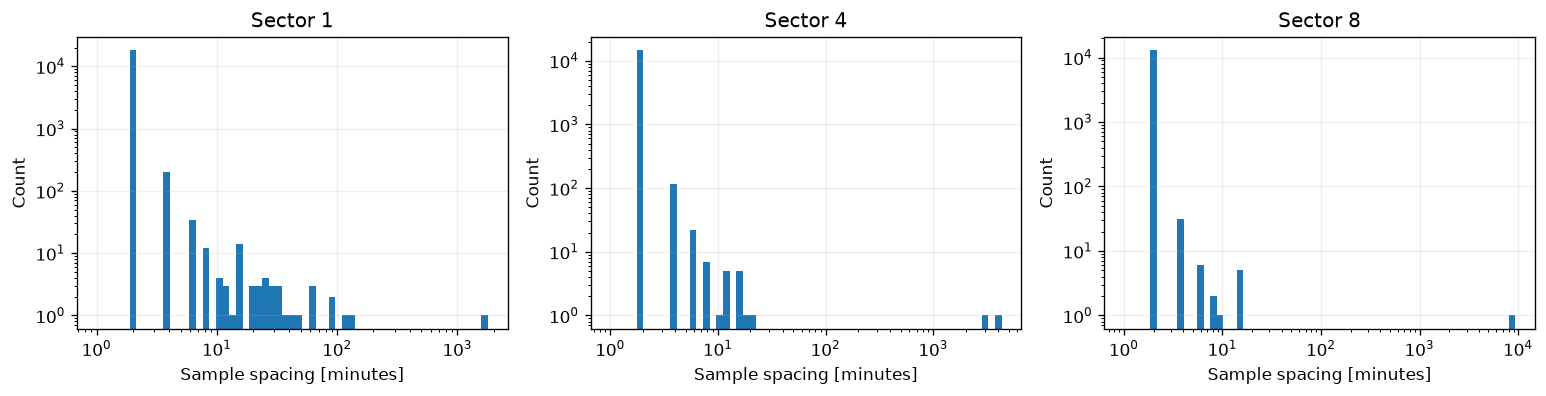

,sector,start_btjd,end_btjd,gap_hours
63,8,1529.064223,1534.997669,142.402706
53,4,1418.486672,1421.213005,65.431984
54,4,1422.464367,1424.554597,50.165514
5,1,1338.521779,1339.656478,27.232796
27,1,1348.643825,1348.731323,2.099961
14,1,1348.003559,1348.088280,2.033297
42,1,1349.241036,1349.306313,1.566637
41,1,1349.139649,1349.199370,1.433307
23,1,1348.432718,1348.478550,1.099980
21,1,1348.272999,1348.317442,1.066647


,previous_sector,next_sector,gap_days
0,1,4,57.725045
1,4,8,81.566592


In [6]:
gap_records = []
fig, axes = plt.subplots(1, len(sectors), figsize=(13, 3.4), squeeze=False)
for ax, sector in zip(axes[0], sectors):
    time = clean.loc[clean.sector == sector, 'time'].to_numpy()
    dt = np.diff(time)
    ax.hist(dt * 24 * 60, bins=np.geomspace(1, max(3, dt.max() * 24 * 60) * 1.1, 60))
    ax.set(xscale='log', yscale='log', title=f'Sector {sector}', xlabel='Sample spacing [minutes]', ylabel='Count')
    for i in np.flatnonzero(dt > 10 / (24 * 60)):
        gap_records.append({'sector': int(sector), 'start_btjd': time[i], 'end_btjd': time[i + 1], 'gap_hours': dt[i] * 24})
fig.tight_layout()
fig.savefig(REPORTS / '02_sampling_gaps.png', dpi=150)
plt.show()
gaps = pd.DataFrame(gap_records, columns=['sector', 'start_btjd', 'end_btjd', 'gap_hours'])
gaps.to_csv(REPORTS / 'within_sector_gaps.csv', index=False)
display(gaps.sort_values('gap_hours', ascending=False).head(12))
bounds = clean.groupby('sector').time.agg(['min', 'max'])
cross_sector = pd.DataFrame({'previous_sector': sectors[:-1], 'next_sector': sectors[1:],
                            'gap_days': bounds['min'].to_numpy()[1:] - bounds['max'].to_numpy()[:-1]})
display(cross_sector)

## 5. Compare scatter and reported uncertainty

`robust_scatter_ppm` is 1.4826 × median absolute deviation of normalized flux, in parts per million. It includes stellar variability and residual instrumental trends as well as measurement noise.

`adjacent_difference_ppm` uses the robust scatter of differences between retained samples less than three minutes apart, divided by √2. It approximates short-timescale scatter, assuming comparable, independent noise in adjacent measurements. It is **not CDPP** or a transit detection significance. Reported errors need not account for correlated noise.

In [7]:
def robust_sigma(values):
    values = np.asarray(values)
    return 1.4826 * np.median(np.abs(values - np.median(values)))

summary_rows = []
for sector in sectors:
    part = clean[clean.sector == sector]
    source = raw[raw.sector == sector]
    flux = part.pdcsap_flux_norm.to_numpy()
    dt = np.diff(part.time.to_numpy())
    near = (dt > 0) & (dt < 3 / (24 * 60))
    summary_rows.append({
        'sector': int(sector), 'original_rows': len(source), 'retained_rows': len(part),
        'retained_percent': 100 * len(part) / len(source),
        'span_days': part.time.max() - part.time.min(),
        'median_cadence_seconds': np.median(dt) * 86400,
        'robust_scatter_ppm': robust_sigma(flux) * 1e6,
        'adjacent_difference_ppm': robust_sigma(np.diff(flux)[near]) / np.sqrt(2) * 1e6,
        'median_reported_error_ppm': part.pdcsap_flux_err_norm.median() * 1e6,
        'gaps_over_10min': int((dt > 10 / (24 * 60)).sum()),
    })
summary = pd.DataFrame(summary_rows)
summary.to_csv(REPORTS / 'eda_summary.csv', index=False)
display(summary.round(2))

,sector,original_rows,retained_rows,retained_percent,span_days,median_cadence_seconds,robust_scatter_ppm,adjacent_difference_ppm,median_reported_error_ppm,gaps_over_10min
0,1,20076,18264,90.97,27.88,120.0,125.489998,112.26,89.099998,45
1,4,18684,14642,78.37,25.51,120.0,191.589996,124.51,88.750000,14
2,8,17755,12935,72.85,24.02,120.0,214.649994,183.99,88.610001,7


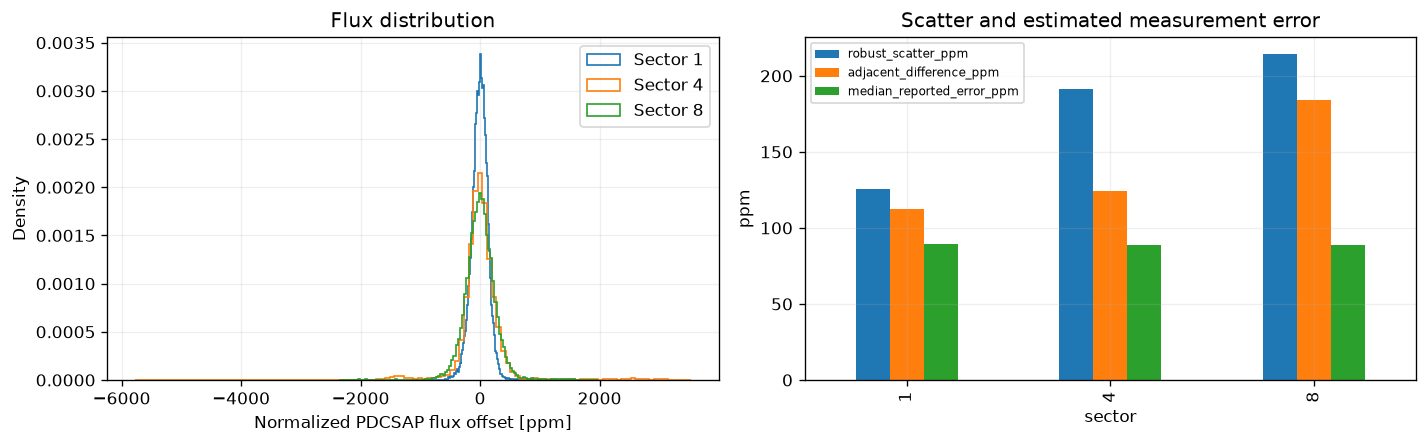

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for sector in sectors:
    part = clean[clean.sector == sector]
    axes[0].hist((part.pdcsap_flux_norm - 1) * 1e6, bins=120, histtype='step', density=True, label=f'Sector {sector}')
axes[0].set(xlabel='Normalized PDCSAP flux offset [ppm]', ylabel='Density', title='Flux distribution')
axes[0].legend()
summary.set_index('sector')[['robust_scatter_ppm', 'adjacent_difference_ppm', 'median_reported_error_ppm']].plot.bar(ax=axes[1])
axes[1].set(title='Scatter and estimated measurement error', ylabel='ppm')
axes[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(REPORTS / '03_flux_and_noise.png', dpi=150)
plt.show()

## 6. Inspect one sector at closer range

This shows a two-day interval from the first sector. The orange points are inverse-variance weighted averages in ten-minute bins, used only to make the plot readable. Binning is not applied to the saved data. Change `zoom_start` and `zoom_days` to inspect another interval. Individual downward excursions still need investigation.

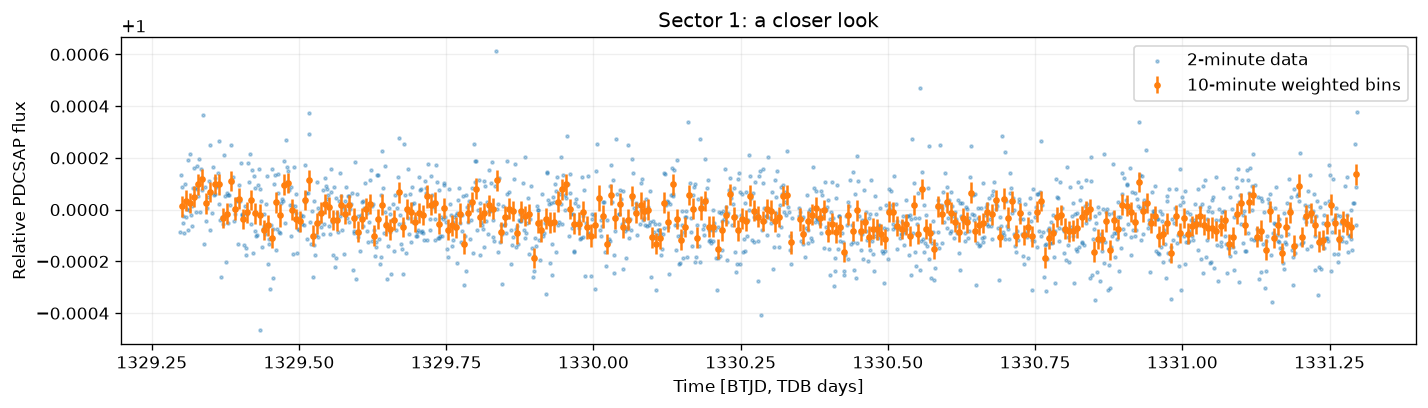

In [9]:
sector = sectors[0]
part = clean[clean.sector == sector]
zoom_start = float(part.time.min()) + 4
zoom_days = 2
zoom = part[part.time.between(zoom_start, zoom_start + zoom_days)].copy()
zoom['bin'] = np.floor((zoom.time - zoom_start) * 24 * 6).astype(int)
zoom['weight'] = 1 / zoom.pdcsap_flux_err_norm**2
zoom['weighted_flux'] = zoom.pdcsap_flux_norm * zoom.weight
binned = zoom.groupby('bin').agg(time=('time', 'mean'), weighted_flux=('weighted_flux', 'sum'), weight=('weight', 'sum'))
binned['flux'] = binned.weighted_flux / binned.weight
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.scatter(zoom.time, zoom.pdcsap_flux_norm, s=3, alpha=0.35, label='2-minute data')
ax.errorbar(binned.time, binned.flux, yerr=1 / np.sqrt(binned.weight), fmt='.', color='tab:orange', label='10-minute weighted bins')
ax.set(title=f'Sector {sector}: a closer look', xlabel='Time [BTJD, TDB days]', ylabel='Relative PDCSAP flux')
ax.legend()
fig.tight_layout()
fig.savefig(REPORTS / '04_zoom.png', dpi=150)
plt.show()

In [10]:
report_lines = [
    '# TESS starter-data EDA', '',
    'Target: Pi Mensae (TIC 261136679). Public MAST/SPOC 120-second light curves.', '',
    f'Original cadences: {len(raw):,}. Retained: {len(clean):,} ({100 * len(clean) / len(raw):.1f}%).',
    f'Quality policy: Lightkurve default bitmask {QUALITY_BITMASK}, finite/positive PDCSAP flux and uncertainty.', '',
    '| Sector | Retained rows | Span (days) | Robust scatter (ppm) | Adjacent difference (ppm) | Reported error (ppm) |',
    '| --- | ---: | ---: | ---: | ---: | ---: |',
]
for row in summary.itertuples():
    report_lines.append(f'| {row.sector} | {row.retained_rows:,} | {row.span_days:.2f} | {row.robust_scatter_ppm:.1f} | {row.adjacent_difference_ppm:.1f} | {row.median_reported_error_ppm:.1f} |')
report_lines += ['', 'Spans include observing gaps; they are not uninterrupted exposure times. Scatter is not CDPP or detection significance.', '',
                 'The original FITS files and all-cadence CSV retain missing values and flags. The clean CSV has only minimal quality filtering and per-sector normalization. No detrending, sigma clipping, gap interpolation, or period search has been applied.', '',
                 'Next: inspect anomalies, test per-sector detrending, then run a blind Box Least Squares search and examine individual events and the phase-folded curve.']
(REPORTS / 'eda_notes.md').write_text('\n'.join(report_lines) + '\n')
print('Saved CSVs to data/processed and figures/summary to reports/.')

Saved CSVs to data/processed and figures/summary to reports/.


## Your next investigation

1. Compare SAP and PDCSAP. Which trends did the pipeline remove? Are downward excursions preserved?
2. Compare sector-level scatter against reported errors. Where does variability exceed nominal uncertainty?
3. Inspect the largest gaps and flagged intervals. Keep them out of any assumed regular time grid.
4. Try different quality masks and quantify how many cadences change.
5. Then build a **blind BLS search**: detrend sectors separately, preserve potential dips, search a broad period range, and inspect several peaks and their harmonics. No orbital period is supplied in this notebook.

These three sectors belong to **one known planet host**, not an unbiased stellar survey or an ML training set. When you expand, select stars explicitly and split evaluation by star. Pixel-level contamination checks and false-positive vetting come after initial signal detection.

References: [MAST TESS archive](https://archive.stsci.edu/missions-and-data/tess), [NASA hands-on tutorial](https://heasarc.gsfc.nasa.gov/docs/tess/HowToFindAnExoplanet-UserVersion.html), [Lightkurve data search API](https://lightkurve.github.io/lightkurve/reference/api/lightkurve.search_lightcurve.html).